   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 935.6/935.6 kB 12.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 692.3/692.3 kB 20.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [uproot]


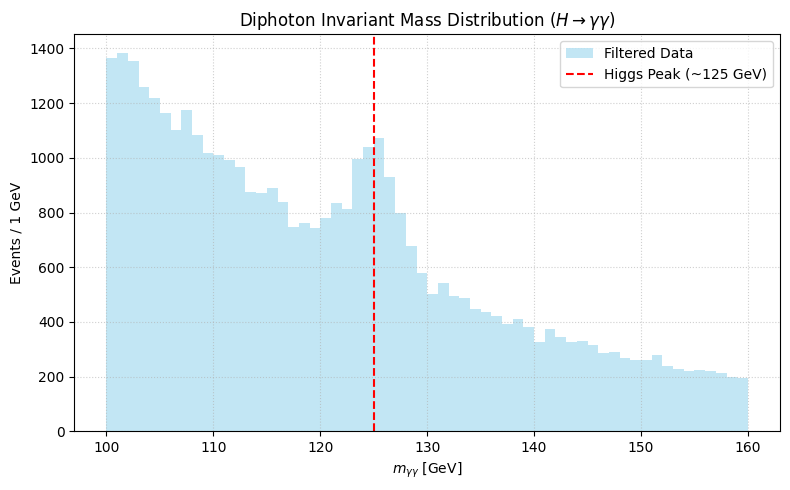

In [1]:
!pip install uproot

import numpy as np
import pandas as pd
import uproot
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Generate synthetic diphoton dataset
np.random.seed(42)
n_events = 50000

bkg_mass = np.random.exponential(scale=30, size=int(n_events * 0.95)) + 100
sig_mass = np.random.normal(loc=125.0, scale=2.0, size=int(n_events * 0.05))
m_gg = np.concatenate([bkg_mass, sig_mass])

df = pd.DataFrame({
    'pt1': np.random.uniform(30, 80, len(m_gg)),
    'pt2': np.random.uniform(25, 70, len(m_gg)),
    'm_gg': m_gg
})

with uproot.recreate("higgs_sample.root") as f:
    f["Events"] = df

# ROOT tree and apply baseline photon pT cuts
with uproot.open("higgs_sample.root") as f:
    events = f["Events"].arrays(["pt1", "pt2", "m_gg"], library="pd")

cut = (events['pt1'] > 35.0) & (events['pt2'] > 25.0)
mass = events.loc[cut, 'm_gg']

# invariant mass distribution after kinematic cuts
plt.figure(figsize=(8, 5))
plt.hist(mass, bins=60, range=(100, 160), histtype='stepfilled', alpha=0.5, color='skyblue', label='Filtered Data')
plt.axvline(125.0, color='red', linestyle='--', label='Higgs Peak (~125 GeV)')
plt.xlabel(r'$m_{\gamma\gamma}$ [GeV]')
plt.ylabel('Events / 1 GeV')
plt.title(r'Diphoton Invariant Mass Distribution ($H \to \gamma\gamma$)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

ROOT File successfully created!


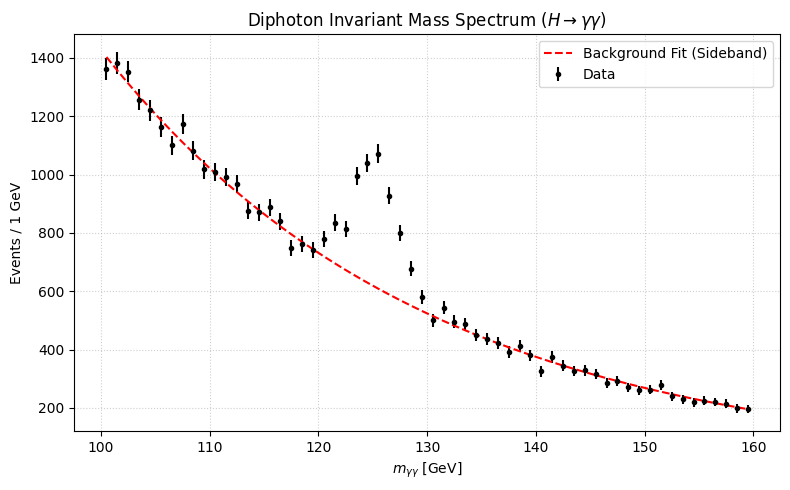

Observed events (122-128 GeV): 5647
Estimated Bkg: 3719
Signal Yield: 1927


In [3]:


# Generate synthetic toy data for diphoton channel
np.random.seed(42)
N = 50000

# Exponential bkg + Gaussian Higgs signal peak
bkg_m = np.random.exponential(scale=30, size=int(N * 0.95)) + 100
sig_m = np.random.normal(loc=125.0, scale=2.0, size=int(N * 0.05))
m_gg = np.concatenate([bkg_m, sig_m])

df = pd.DataFrame({
    'pt1': np.random.uniform(30, 80, len(m_gg)),
    'pt2': np.random.uniform(25, 70, len(m_gg)),
    'm_gg': m_gg
})

with uproot.recreate("higgs_sample.root") as f:
    f["Events"] = df

print("ROOT File successfully created!")

# Read back root tree
f = uproot.open("higgs_sample.root")
t = f["Events"]
events = t.arrays(["pt1", "pt2", "m_gg"], library="pd")

# Kinematic baseline cuts
cut = (events['pt1'] > 35.0) & (events['pt2'] > 25.0)
df_cut = events[cut]
mass = df_cut['m_gg']

# sideband background fit
counts, edges = np.histogram(mass, bins=60, range=(100, 160))
centers = 0.5 * (edges[:-1] + edges[1:])

def bkg_func(x, a, b):
    return a * np.exp(-b * (x - 100))

sideband_mask = (centers < 120) | (centers > 130)
popt, _ = curve_fit(bkg_func, centers[sideband_mask], counts[sideband_mask], p0=[1000, 0.02])
bkg_fit = bkg_func(centers, *popt)

# Plotting m_gg distribution
plt.figure(figsize=(8, 5))
plt.errorbar(centers, counts, yerr=np.sqrt(counts), fmt='o', color='black', ms=3, label='Data')
plt.plot(centers, bkg_fit, 'r--', label='Background Fit (Sideband)')

plt.xlabel(r'$m_{\gamma\gamma}$ [GeV]')
plt.ylabel('Events / 1 GeV')
plt.title(r'Diphoton Invariant Mass Spectrum ($H \to \gamma\gamma$)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Signal yield
peak_mask = (centers >= 122) & (centers <= 128)
n_obs = np.sum(counts[peak_mask])
n_bkg = np.sum(bkg_fit[peak_mask])
n_sig = n_obs - n_bkg

print(f"Observed events (122-128 GeV): {int(n_obs)}")
print(f"Estimated Bkg: {int(n_bkg)}")
print(f"Signal Yield: {int(n_sig)}")